In [2]:
from sc_scripts import *
import scanpy as sc
import pandas as pd
import numpy as np
import anndata as ad
from pathlib import Path
import os
import json

path = Path("part_2")

res = 0.1
n_components = 30

# Breast cancer metastasis (met)

In [113]:
type = "breast_met"
data_path = path / type

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_2/breast_met/1'),
 PosixPath('part_2/breast_met/2'),
 PosixPath('part_2/breast_met/3'),
 PosixPath('part_2/breast_met/4'),
 PosixPath('part_2/breast_met/5')]

Integration concat join='outer': per-sample genes [33538, 33538, 33538, 33538, 30197] -> combined 29256 genes × 18413 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-29 14:39:16,519 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-29 14:39:17,338 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-29 14:39:17,359 - harmonypy - INFO - Iteration 1 of 10
2026-10-29 14:39:18,822 - harmonypy - INFO - Iteration 2 of 10
2026-10-29 14:39:20,515 - harmonypy - INFO - Iteration 3 of 10
2026-10-29 14:39:21,90

*********************
18413 cells, 29256 genes
*********************


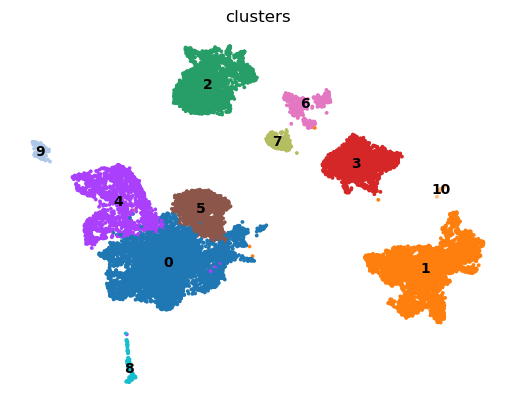

In [5]:
adata = run_pipeline_integrate(paths, n_components=50, resolution=0.2, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [6]:
adata = adata[~adata.obs['clusters'].isin(['10'])].copy()

In [ ]:
cluster_annotation = {
    "0": "Malignant cells",
    "1": "T cells",
    "2": "Macrophages",
    "3": "B cells",
    "4": "Malignant cells", # HOX-high malignant cells
    "5": "Malignant cells", # Luminal malignant cells
    "6": "Germinal center B cells",
    "7": "Plasma cells",
    "8": "Fibroblasts",
    "9": "Endothelial cells",
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType               
0         Malignant cells            6483
1         T cells                    3642
2         Macrophages                2339
3         B cells                    1824
4         Malignant cells            1657
5         Malignant cells            1582
6         Germinal center B cells     402
7         Plasma cells                224
8         Fibroblasts                 115
9         Endothelial cells           102
Name: count, dtype: int64

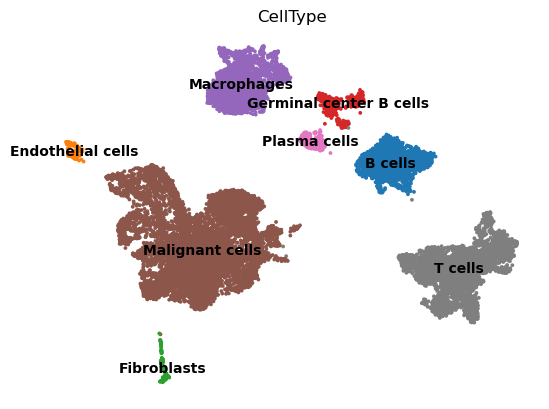

In [8]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

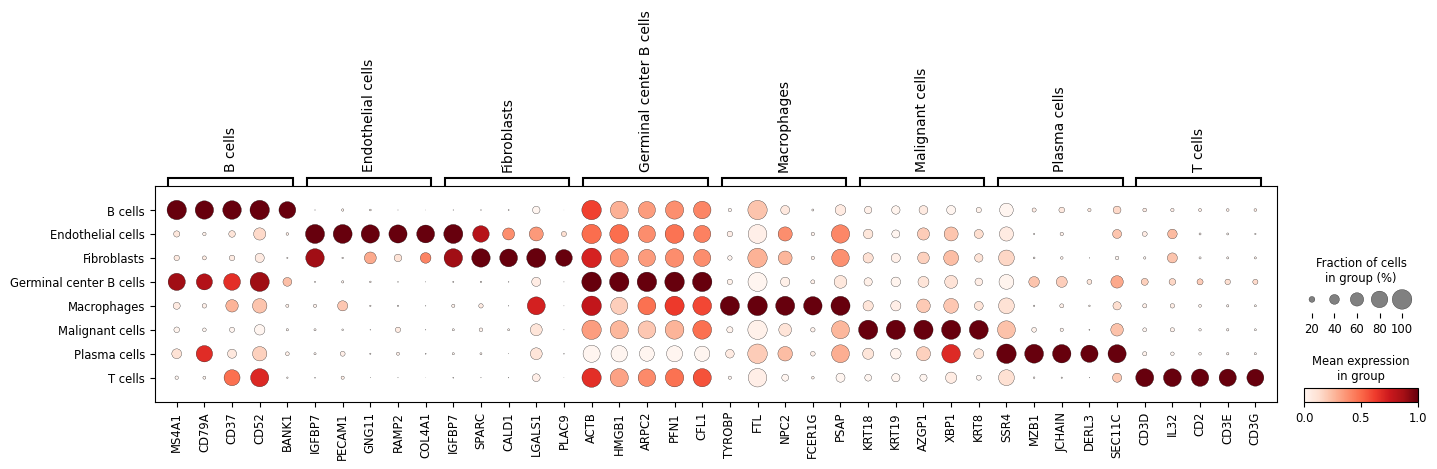

In [9]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=5)

In [10]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Renal cell cancer met

In [ ]:
type = "RCC_met"
data_path = path / type

paths = [data_path / str(i) / os.listdir(data_path / str(i))[0]for i in range(1, 7)]
paths

[PosixPath('part_2/RCC_met/1/GSM6133741_RCC-BM3-Tumor.count.csv.gz'),
 PosixPath('part_2/RCC_met/2/GSM6133742_RCC-BM4-Tumor.count.csv.gz'),
 PosixPath('part_2/RCC_met/3/GSM6133743_RCC-BM5-Tumor.count.csv.gz'),
 PosixPath('part_2/RCC_met/4/GSM6133744_RCC-BM7-Tumor.count.csv.gz'),
 PosixPath('part_2/RCC_met/5/GSM6133745_RCC-BM8-Tumor.count.csv.gz'),
 PosixPath('part_2/RCC_met/6/GSM6133749_RCC-BM2-Tumor.count.csv.gz')]

Integration concat join='outer': per-sample genes [32738, 32738, 32738, 32738, 32738, 32738] -> combined 22105 genes × 17154 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-29 15:13:23,848 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-29 15:13:24,489 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-29 15:13:24,516 - harmonypy - INFO - Iteration 1 of 10
2026-10-29 15:13:25,677 - harmonypy - INFO - Iteration 2 of 10
2026-10-29 15:13:26,857 - harmonypy - INFO - Iteration 3 of 10
2026-10-29 15:13:28,128 - harmonypy - INFO - Iteration 4 of 10
2026-10-29 15:13:29,250 - harmonypy - INFO - Iteration 5 of 10
2026-10-29 15:13:30,393 - harmonypy - INFO - Iteration 6 of 10
2026-10-29 15:13:31,561 - harmonypy

*********************
17154 cells, 22105 genes
*********************


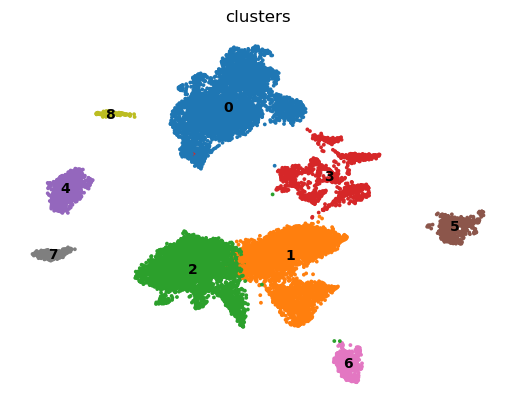

In [18]:
adata = run_pipeline_integrate(paths, n_components=n_components, resolution=res, is_10x=False)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [19]:
# Filtering out the low quality cells
adata = adata[~adata.obs["clusters"].isin(["3"])].copy() 

In [20]:
cluster_annotation = {
    "0": "Macrophages and monocytes",
    "1": "NK cells",
    "2": "T cells",

    "4": "B cells",
    "5": "Fibroblasts",
    "6": "Malignant cells",
    "7": "Plasma cells",
    "8": "Endothelial cells",
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                 
0         Macrophages and monocytes    4971
1         NK cells                     4486
2         T cells                      4431
4         B cells                       859
5         Fibroblasts                   453
6         Malignant cells               350
7         Plasma cells                  265
8         Endothelial cells             112
Name: count, dtype: int64

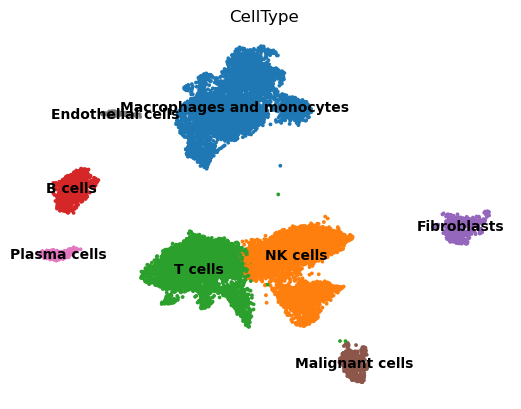

In [21]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

## copyKAT check

In [ ]:
import subprocess
from pathlib import Path
import pandas as pd
from scipy import io, sparse

out = Path(path / type / "copykat")
out.mkdir(parents=True, exist_ok=True)

max_per_type = 1000
parts = []
for cell_type, idx in adata.obs.groupby("CellType", observed=True).groups.items():
    idx = pd.Index(idx)
    if len(idx) > max_per_type:
        idx = idx.to_series().sample(max_per_type, random_state=0).index
    parts.append(idx)
keep = pd.Index(parts).union(pd.Index([])) if False else parts[0]
for part in parts[1:]:
    keep = keep.append(part)
sub = adata[keep].copy()

counts = sub.layers["counts"]
mat = counts.T.tocsr() if sparse.issparse(counts) else sparse.csr_matrix(counts.T)
io.mmwrite(out / "counts.mtx", mat)
pd.Series(sub.var_names).to_csv(out / "genes.tsv", index=False, header=False)
pd.Series(sub.obs_names).to_csv(out / "barcodes.tsv", index=False, header=False)
ref = sub.obs_names[sub.obs["CellType"].isin(["T cells", "B cells", "Plasma cells"])]
pd.Series(ref).to_csv(out / "normal_cells.tsv", index=False, header=False)
sub.obs[["CellType"]].to_csv(out / "celltype.tsv", sep="\t")


(out / "run_copykat.R").write_text(r"""
library(Matrix)
library(copykat)
setwd("part_2/ccRCC-BM/copykat")
mat <- as.matrix(readMM("counts.mtx"))
rownames(mat) <- readLines("genes.tsv")
colnames(mat) <- readLines("barcodes.tsv")
normal <- readLines("normal_cells.tsv")
ck <- copykat(
  rawmat = mat,
  id.type = "S",
  cell.line = "no",
  genome = "hg20",
  norm.cell.names = normal,
  KS.cut = 0.1,
  sam.name = "RCC_BM",
  n.cores = 4
)
saveRDS(ck, "RCC_BM_copykat.rds")
pred <- ck$prediction
meta <- read.delim("celltype.tsv", row.names = 1)
pred$CellType <- meta[pred$cell.names, "CellType"]
write.table(pred, "RCC_BM_prediction.tsv", sep = "\t", quote = FALSE, row.names = FALSE)
print(table(pred$CellType, pred$copykat.pred))
""")

subprocess.run(["/usr/local/bin/Rscript", str(out / "run_copykat.R")], check=True)
print(pd.read_csv(out / "RCC_BM_prediction.tsv", sep="\t").groupby(["CellType", "copykat.pred"]).size())


[1] "running copykat v1.1.0"
[1] "step1: read and filter data ..."
[1] "22105 genes, 5039 cells in raw data"
[1] "6105 genes past LOW.DR filtering"
[1] "WARNING: low data quality; assigned LOW.DR to UP.DR..."
[1] "step 2: annotations gene coordinates ..."
[1] "start annotation ..."
[1] "step 3: smoothing data with dlm ..."
[1] "step 4: measuring baselines ..."
[1] "1436 known normal cells found in dataset"
[1] "run with known normal..."
[1] "baseline is from known input"
[1] "step 5: segmentation..."
[1] "step 6: convert to genomic bins..."
[1] "step 7: adjust baseline ..."
[1] "step 8: final prediction ..."
[1] "step 9: saving results..."
[1] "step 10: ploting heatmap ..."
Time difference of 15.37856 mins
                           
                            aneuploid diploid not.defined
  B cells                           0     474         385
  Endothelial cells                 0     106           6
  Fibroblasts                       3     422          28
  Macrophages and monocy

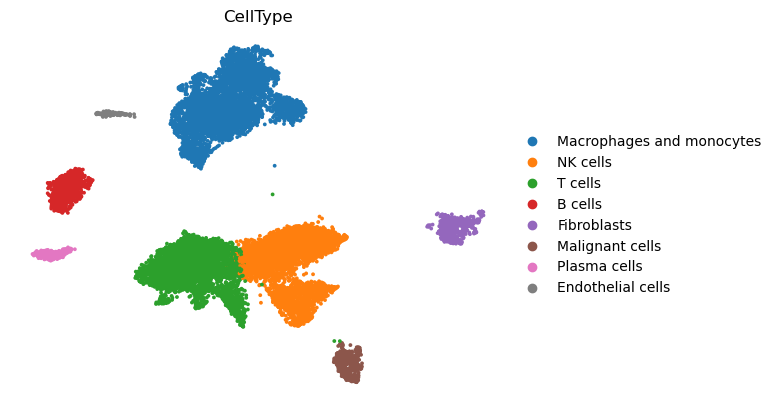

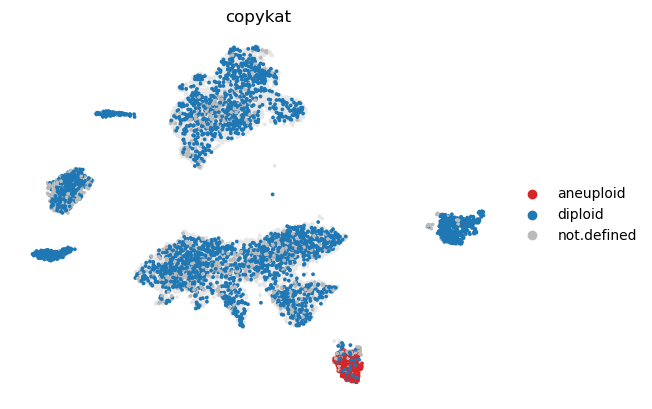

copykat,aneuploid,diploid,not.defined
CellType,,,
Macrophages and monocytes,0.000,0.792,0.208
NK cells,0.000,0.768,0.232
T cells,0.000,0.709,0.291
B cells,0.000,0.552,0.448
Fibroblasts,0.007,0.932,0.062
Malignant cells,0.723,0.123,0.154
Plasma cells,0.000,0.955,0.045
Endothelial cells,0.000,0.946,0.054


In [ ]:
pred = pd.read_csv("part_2/ccRCC-BM/copykat/RCC_BM_prediction.tsv", sep="\t")
adata.obs["copykat"] = pd.Categorical(
    pred.set_index("cell.names")["copykat.pred"].reindex(adata.obs_names),
    categories=["aneuploid", "diploid", "not.defined"],
)
sc.pl.umap(adata, color="CellType", size=30, alpha=1, frameon=False)

sc.pl.umap(
    adata,
    color="copykat",
    palette={"aneuploid": "#d62728", "diploid": "#1f77b4", "not.defined": "#bbbbbb"},
    na_color="#e6e6e6",
    na_in_legend=False,
    size=30,
    alpha=1,
    frameon=False,
)

pd.crosstab(adata.obs["CellType"], adata.obs["copykat"], normalize="index").round(3)

/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scan

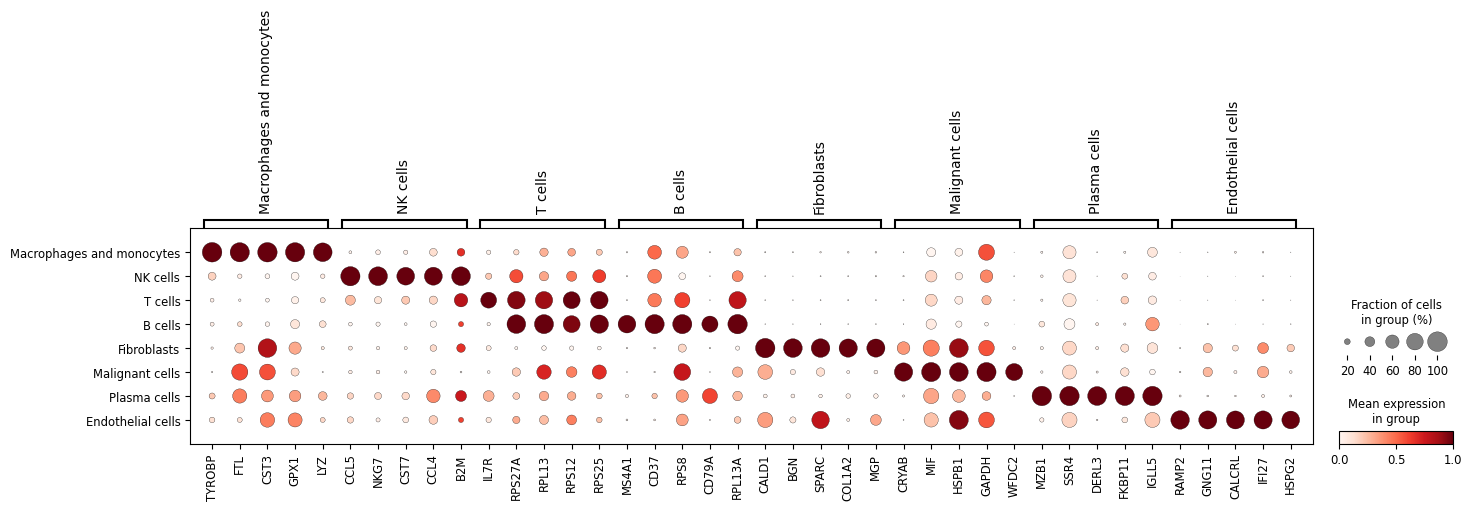

In [25]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=5)

In [26]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Colorectal cancer mets

In [111]:
type = "colorectal_met"
data_path = path / type

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_2/colorectal_met/1'),
 PosixPath('part_2/colorectal_met/2'),
 PosixPath('part_2/colorectal_met/3'),
 PosixPath('part_2/colorectal_met/4'),
 PosixPath('part_2/colorectal_met/5')]

Integration concat join='outer': per-sample genes [33538, 33538, 36601, 36601, 36601] -> combined 26067 genes × 26846 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-29 16:36:26,268 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-29 16:36:27,249 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-29 16:36:27,287 - harmonypy - INFO - Iteration 1 of 10
2026-10-29 16:36:29,712 - harmonypy - INFO - Iteration 2 of 10
2026-10-29 16:36:31,930 - harmonypy - INFO - Iteration 3 of 10
2026-10-29 16:36:34,37

*********************
26846 cells, 26067 genes
*********************


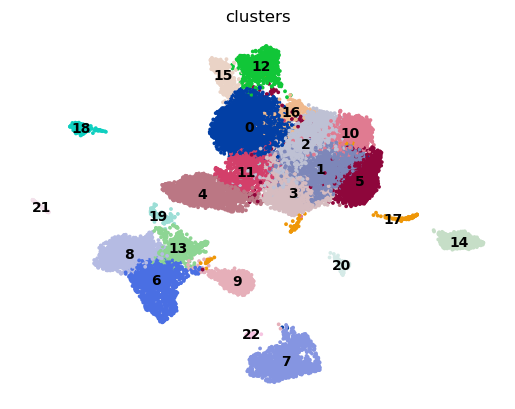

In [34]:
adata = run_pipeline_integrate(paths, n_components=40, resolution=1, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [35]:
adata = adata[~adata.obs['clusters'].isin(['9', '17', '19', '22', '21', '5'])].copy()

In [36]:
cluster_annotation = {
    "0": "T cells",
    "1": "T cells",
    "2": "T cells",
    "3": "T cells",
    "4": "T cells",
    "5": "T cells",
    "10": "T cells",
    "11": "T cells",
    "16": "T cells",
    "12": "NK cells",
    "15": "NK cells",
    
    "14": "B cells",
    "18": "Plasma cells",
    "20": "Fibroblasts",

    "6": "Monocytes",
    "8": "Macrophages",
    "13": "Dendritic cells",
    
    "7": "Malignant cells",



}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType       
0         T cells            4122
1         T cells            3949
2         T cells            2273
3         T cells            2114
4         T cells            1715
6         Monocytes          1451
7         Malignant cells    1402
8         Macrophages        1328
10        T cells            1241
11        T cells             933
12        NK cells            851
13        Dendritic cells     714
14        B cells             504
15        NK cells            405
16        T cells             271
18        Plasma cells        170
20        Fibroblasts          88
Name: count, dtype: int64

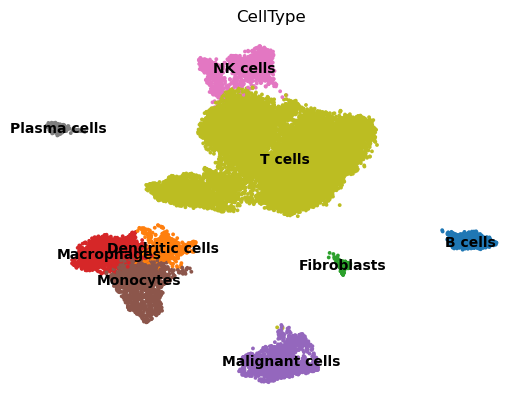

In [37]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

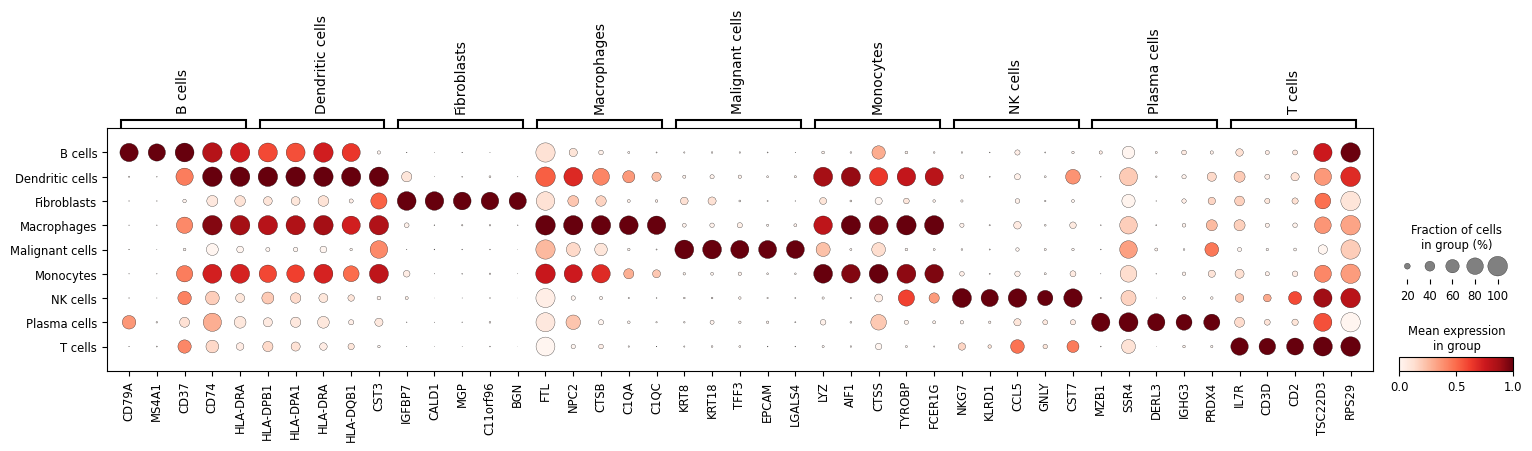

In [38]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=5)

In [39]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Gastric cancer met

In [5]:
type = "GC_met"
data_path = path / type

paths = [data_path / str(i) / os.listdir(data_path / str(i))[0] for i in range(1, 5)]
paths

[PosixPath('part_2/GC_met/1/GSM5573485_sample20.csv.gz'),
 PosixPath('part_2/GC_met/2/GSM5573503_sample38.csv.gz'),
 PosixPath('part_2/GC_met/3/GSM7874175_LM1.csv.gz'),
 PosixPath('part_2/GC_met/4/GSM7874176_LM2.csv.gz')]

Integration concat join='outer': per-sample genes [26571, 26571, 22728, 27614] -> combined 25937 genes × 17909 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-29 18:05:31,115 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-29 18:05:31,685 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-29 18:05:31,706 - harmonypy - INFO - Iteration 1 of 10
2026-10-29 18:05:33,220 - harmonypy - INFO - Iteration 2 of 10
2026-10-29 18:05:34,630 - harmonypy - INFO - Iteration 3 of 10
2026-10-29 18:05:35,831 - harmonypy - INFO - Iteration 4 of 10
2026-10-29 18:05:36,930 - harmonypy - INFO - Converged after 4 iterations
/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:368: FutureWarni

*********************
17909 cells, 25937 genes
*********************


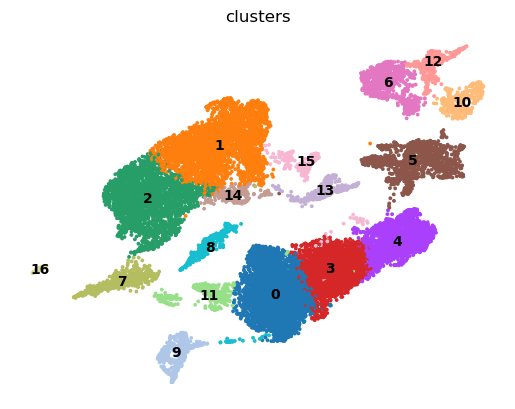

In [75]:
adata = run_pipeline_integrate(paths, n_components=20, resolution=0.4, is_10x=False)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [79]:
adata = adata[~adata.obs['clusters'].isin(['13', '14', '15', '11', '16', '6', '8'])].copy()

In [80]:
cluster_annotation = {
    "0": "T cells",
    "1": "Macrophages",
    "2": "Monocytes",
    "3": "T cells",
    "4": "T cells",
    "5": "Endothelial cells",

    "7": "Neutrophils",

    "9": "Malignant cells",
    "10": "Pericytes",
    "12": "Fibroblasts",
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType         
0         T cells              3343
1         Macrophages          2966
2         Monocytes            2463
3         T cells              2210
4         T cells              1711
5         Endothelial cells    1218
7         Neutrophils           566
9         Malignant cells       369
10        Pericytes             368
12        Fibroblasts           341
Name: count, dtype: int64

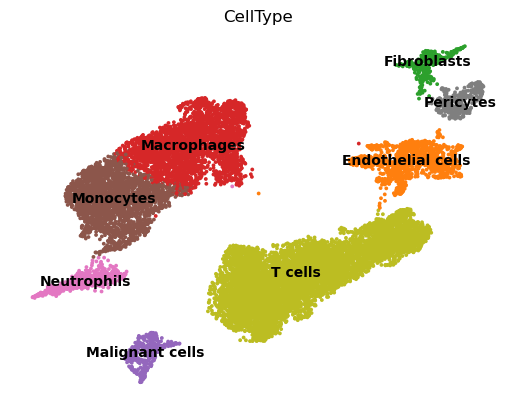

In [81]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scan

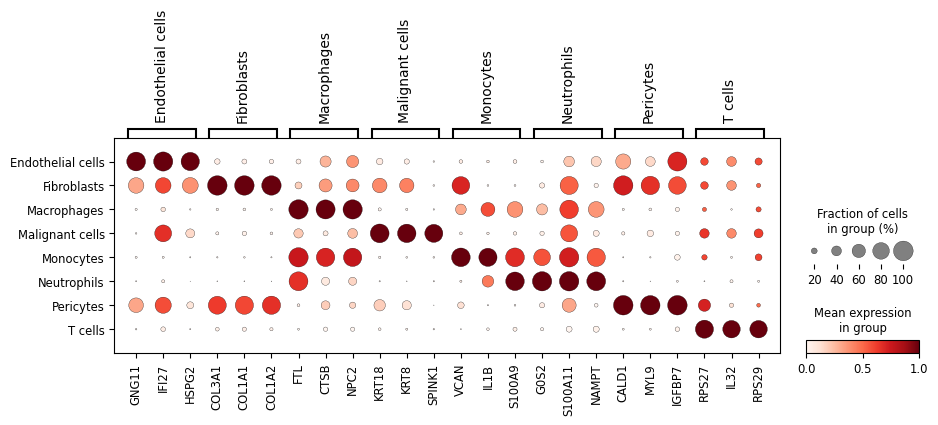

In [82]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=3)

In [83]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# glioblastoma

In [109]:
type = "glioblastoma"
data_path = path / type

paths = [data_path / str(i) / os.listdir(data_path / str(i))[0] for i in range(1, 9)]
paths

[PosixPath('part_2/glioblastoma/1/GSM2758471_PJ016.filtered.matrix.txt.gz'),
 PosixPath('part_2/glioblastoma/2/GSM2758472_PJ017.filtered.matrix.txt.gz'),
 PosixPath('part_2/glioblastoma/3/GSM2758473_PJ018.filtered.matrix.txt.gz'),
 PosixPath('part_2/glioblastoma/4/GSM2758474_PJ025.filtered.matrix.txt.gz'),
 PosixPath('part_2/glioblastoma/5/GSM2758475_PJ030.filtered.matrix.txt.gz'),
 PosixPath('part_2/glioblastoma/6/GSM2758476_PJ032.filtered.matrix.txt.gz'),
 PosixPath('part_2/glioblastoma/7/GSM2758477_PJ035.filtered.matrix.txt.gz'),
 PosixPath('part_2/glioblastoma/8/GSM2940098_PJ048.filtered.matrix.txt.gz')]

In [110]:
import importlib, sc_scripts
importlib.reload(sc_scripts)
from sc_scripts import *

/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/anndata/_core/anndata.py:1825: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:133: UserWarning: Suffix used (-[0-9]+) to deduplicate index values may make index values difficult to interpret. There values with a similar suffixes in the index. Consider using a different delimiter by passing `join={delimiter}`. Example key collisions generated by the make_index_unique algorithm: ['SNORD113-1', 'SNORD113-2', 'SNORD113-3', 'SNORD113-4', 'SNORD113-5']
  
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: ImplicitModificationWar

Integration concat join='outer': per-sample genes [60725, 60725, 60725, 60725, 60725, 60725, 60725, 60725] -> combined 37093 genes × 17217 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-29 19:01:56,480 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-29 19:01:57,195 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-29 19:01:57,215 - harmonypy - INFO - Iteration 1 of 10
2026-10-29 19:01:58,648 - harmonypy - INFO - Iteration 2 of 10
2026-10-29 19:02:00,216 - harmonypy - INFO - Converged after 2 iterations
/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:371: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False

*********************
17217 cells, 37093 genes
*********************


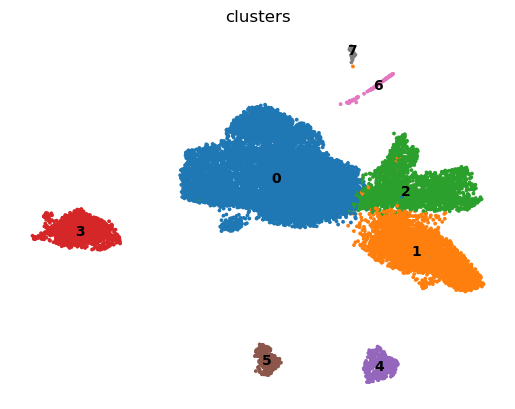

In [118]:
adata = run_pipeline_integrate(paths, n_components=50, resolution=0.1, is_10x=False)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [140]:
adata = adata[~adata.obs['clusters'].isin(['7'])].copy()

In [141]:
cluster_annotation = {
    "0": "Malignant cells",
    "1": "Malignant cells",
    "2": "Malignant cells",
    "3": "Macrophages",
    "4": "Endothelial cells",
    "5": "Pericytes",
    "6": "Oligodendrocytes" 
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType         
0         Malignant cells      9527
1         Malignant cells      3116
2         Malignant cells      2405
3         Macrophages          1327
4         Endothelial cells     375
5         Pericytes             313
6         Oligodendrocytes       93
Name: count, dtype: int64

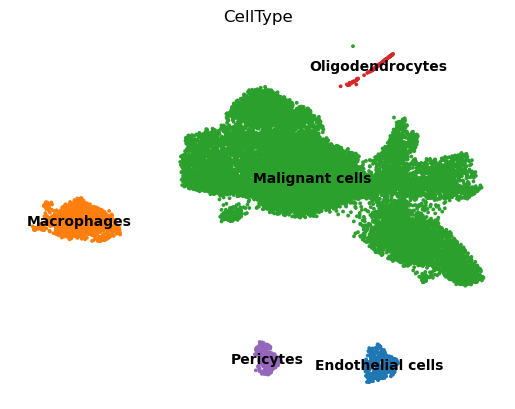

In [142]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scan

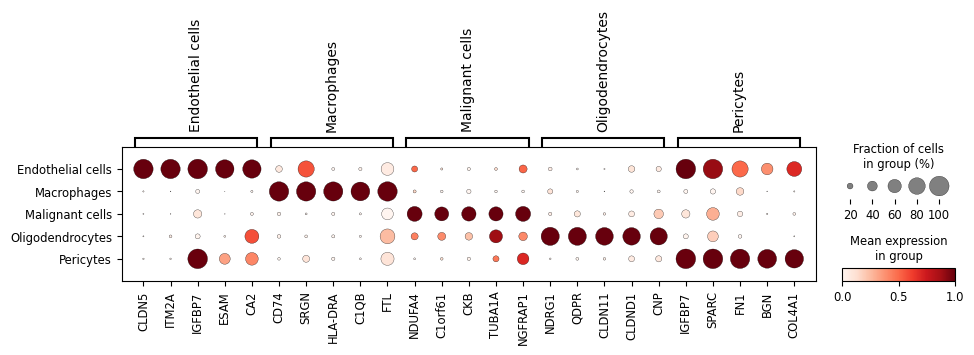

In [143]:
sc.tl.rank_genes_groups(
    adata,
    groupby="CellType",
    method="wilcoxon"
)

plot_dotplot(adata, n_genes=5)

In [144]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Intrahepatic cholangiocarcinoma 

In [108]:
type = "ICC"
data_path = path / type

paths = [data_path / str(i) / os.listdir(data_path / str(i))[0] for i in [1, 2, 3]]
paths

[PosixPath('part_2/ICC/1/GSM4116580_ICC_18_Tumor_UMI.csv.gz'),
 PosixPath('part_2/ICC/2/GSM4116585_ICC_24_Tumor2_UMI.csv.gz'),
 PosixPath('part_2/ICC/3/GSM4116584_ICC_24_Tumor1_UMI.csv.gz')]

Integration concat join='outer': per-sample genes [16423, 16570, 17353] -> combined 18710 genes × 10389 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-30 11:14:06,388 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-30 11:14:06,929 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-30 11:14:06,947 - harmonypy - INFO - Iteration 1 of 10
2026-10-30 11:14:07,673 - harmonypy - INFO - Iteration 2 of 10
2026-10-30 11:14:08,412 - harmonypy - INFO - Converged after 2 iterations
/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:371: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False

*********************
10389 cells, 18710 genes
*********************


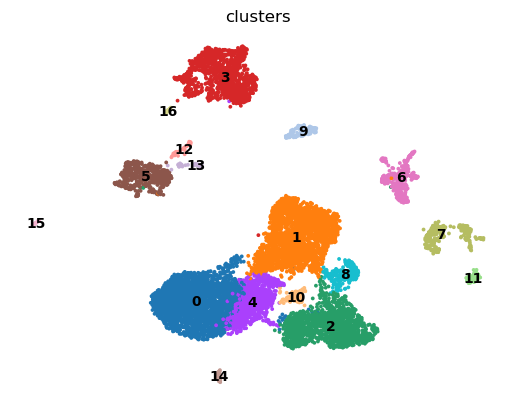

In [13]:
adata = run_pipeline_integrate(paths, n_components=50, resolution=0.4, is_10x=False)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [21]:
adata = adata[~adata.obs['clusters'].isin(['1', '8','10', '12', '13', '14', '15', '16'])].copy()

In [26]:
cluster_annotation = {
    "0": "Malignant cells",

    "2": "Malignant cells [cycling]",
    "4": "Malignant cells",
    '5': 'T cells',
    "3": "Myeloid mononuclear cells",

    "6": "Endothelial cells",
    "7": "Pericytes",

    "9": "Plasma cells",
    "11": "Mesothelial cells"
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                 
0         Malignant cells              2682
2         Malignant cells [cycling]    1480
3         Myeloid mononuclear cells    1234
4         Malignant cells               913
5         T cells                       501
6         Endothelial cells             339
7         Pericytes                     286
9         Plasma cells                  157
11        Mesothelial cells              69
Name: count, dtype: int64

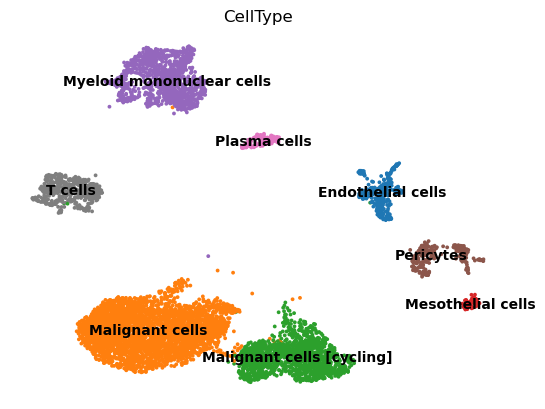

In [27]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [ ]:
import subprocess
from pathlib import Path
import pandas as pd
from scipy import io, sparse

out = Path(path / type / "copykat")
out.mkdir(parents=True, exist_ok=True)

max_per_type = 1000
parts = []
for cell_type, idx in adata.obs.groupby("CellType", observed=True).groups.items():
    idx = pd.Index(idx)
    if len(idx) > max_per_type:
        idx = idx.to_series().sample(max_per_type, random_state=0).index
    parts.append(idx)
keep = pd.Index(parts).union(pd.Index([])) if False else parts[0]
for part in parts[1:]:
    keep = keep.append(part)
sub = adata[keep].copy()

counts = sub.layers["counts"]
mat = counts.T.tocsr() if sparse.issparse(counts) else sparse.csr_matrix(counts.T)
io.mmwrite(out / "counts.mtx", mat)
pd.Series(sub.var_names).to_csv(out / "genes.tsv", index=False, header=False)
pd.Series(sub.obs_names).to_csv(out / "barcodes.tsv", index=False, header=False)
ref = sub.obs_names[sub.obs["CellType"].isin(["T cells", "Myeloid mononuclear cells", "Plasma cells"])]
pd.Series(ref).to_csv(out / "normal_cells.tsv", index=False, header=False)
sub.obs[["CellType"]].to_csv(out / "celltype.tsv", sep="\t")


(out / "run_copykat.R").write_text(r"""
library(Matrix)
library(copykat)
setwd("part_2/ICC/copykat")
mat <- as.matrix(readMM("counts.mtx"))
rownames(mat) <- readLines("genes.tsv")
colnames(mat) <- readLines("barcodes.tsv")
normal <- readLines("normal_cells.tsv")
ck <- copykat(
  rawmat = mat,
  id.type = "S",
  cell.line = "no",
  genome = "hg20",
  norm.cell.names = normal,
  KS.cut = 0.1,
  sam.name = "RCC_BM",
  n.cores = 4
)
saveRDS(ck, "ICC_copykat.rds")
pred <- ck$prediction
meta <- read.delim("celltype.tsv", row.names = 1)
pred$CellType <- meta[pred$cell.names, "CellType"]
write.table(pred, "ICC_prediction.tsv", sep = "\t", quote = FALSE, row.names = FALSE)
print(table(pred$CellType, pred$copykat.pred))
""")

subprocess.run(["/usr/local/bin/Rscript", str(out / "run_copykat.R")], check=True)
print(pd.read_csv(out / "ICC_prediction.tsv", sep="\t").groupby(["CellType", "copykat.pred"]).size())


[1] "running copykat v1.1.0"
[1] "step1: read and filter data ..."
[1] "18710 genes, 5352 cells in raw data"
[1] "10723 genes past LOW.DR filtering"
[1] "step 2: annotations gene coordinates ..."
[1] "start annotation ..."
[1] "step 3: smoothing data with dlm ..."
[1] "step 4: measuring baselines ..."
[1] "1658 known normal cells found in dataset"
[1] "run with known normal..."
[1] "baseline is from known input"
[1] "step 5: segmentation..."
[1] "step 6: convert to genomic bins..."
[1] "step 7: adjust baseline ..."
[1] "step 8: final prediction ..."
[1] "step 9: saving results..."
[1] "step 10: ploting heatmap ..."
Time difference of 35.72997 mins
                           
                            aneuploid diploid not.defined
  Cycling cells                   841     158           1
  Endothelial cells                 0     339           0
  Fibroblasts                       0      69           0
  Malignant cells                 934      63           3
  Myeloid mononuclear cell

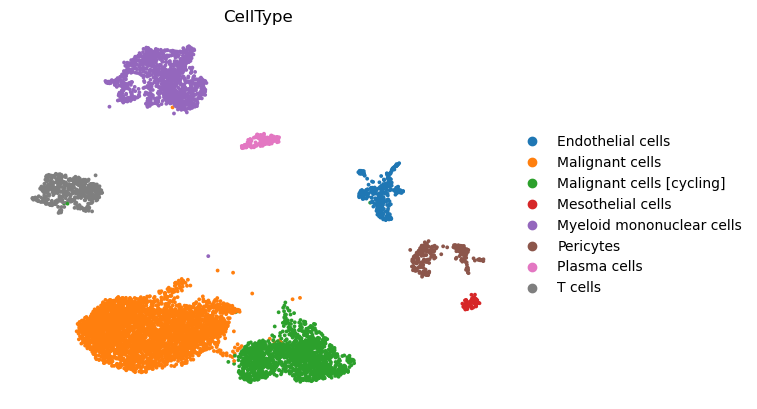

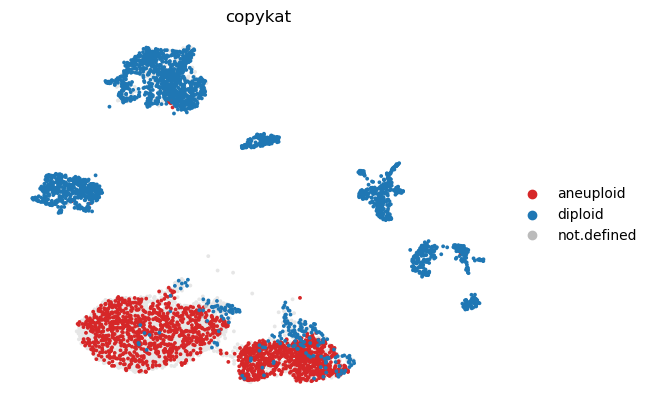

copykat,aneuploid,diploid,not.defined
CellType,,,
Endothelial cells,0.000,1.000,0.000
Malignant cells,0.934,0.063,0.003
Malignant cells [cycling],0.841,0.158,0.001
Mesothelial cells,0.000,1.000,0.000
Myeloid mononuclear cells,0.010,0.990,0.000
Pericytes,0.003,0.997,0.000
Plasma cells,0.006,0.994,0.000
T cells,0.004,0.996,0.000


In [ ]:
pred = pd.read_csv("part_2/ICC/copykat/ICC_prediction.tsv", sep="\t")
adata.obs["copykat"] = pd.Categorical(
    pred.set_index("cell.names")["copykat.pred"].reindex(adata.obs_names),
    categories=["aneuploid", "diploid", "not.defined"],
)
sc.pl.umap(adata, color="CellType", size=30, alpha=1, frameon=False)

sc.pl.umap(
    adata,
    color="copykat",
    palette={"aneuploid": "#d62728", "diploid": "#1f77b4", "not.defined": "#bbbbbb"},
    na_color="#e6e6e6",
    na_in_legend=False,
    size=30,
    alpha=1,
    frameon=False,
)

pd.crosstab(adata.obs["CellType"], adata.obs["copykat"], normalize="index").round(3)

In [29]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# LUAD metastasis

In [2]:
type = "LUAD_met"
data_path = path / type  

paths = [data_path / str(i) / os.listdir(data_path / str(i))[0] for i in range(1, 11)]
paths

[PosixPath('part_2/LUAD_met/1/GSM6112137_LC01.counts.tsv.gz'),
 PosixPath('part_2/LUAD_met/2/GSM6112138_LC02.counts.tsv.gz'),
 PosixPath('part_2/LUAD_met/3/GSM6112139_LC03.counts.tsv.gz'),
 PosixPath('part_2/LUAD_met/4/GSM6112140_LC04.counts.tsv.gz'),
 PosixPath('part_2/LUAD_met/5/GSM6112141_LC05.counts.tsv.gz'),
 PosixPath('part_2/LUAD_met/6/GSM6112142_LC06.counts.tsv.gz'),
 PosixPath('part_2/LUAD_met/7/GSM6112143_LC07.counts.tsv.gz'),
 PosixPath('part_2/LUAD_met/8/GSM6112144_LC08.counts.tsv.gz'),
 PosixPath('part_2/LUAD_met/9/GSM6112145_LC09.counts.tsv.gz'),
 PosixPath('part_2/LUAD_met/10/GSM6112146_LC10.counts.tsv.gz')]

Integration concat join='outer': per-sample genes [32233, 28532, 30367, 30764, 31389, 28806, 28987, 28785, 29531, 26506] -> combined 33865 genes × 34073 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-11-05 21:34:16,452 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-05 21:34:17,821 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-11-05 21:34:17,875 - harmonypy - INFO - Iteration 1 of 10
2026-11-05 21:34:21,136 - harmonypy - INFO - Iteration 2 of 10
2026-11-05 21:34:24,527 - harmonypy - INFO - Iteration 3 of 10
2026-11-05 21:34:28,104 - harmonypy - INFO - Iteration 4 of 10
2026-11-05 21:34:33,265 - harmonypy - INFO - Iteration 5 of 10
2026-11-05 21:34:37,112 - harmonypy - INFO - Iteration 6 of 10
2026-11-05 21:34:39,359 - harmonypy

*********************
34073 cells, 33865 genes
*********************


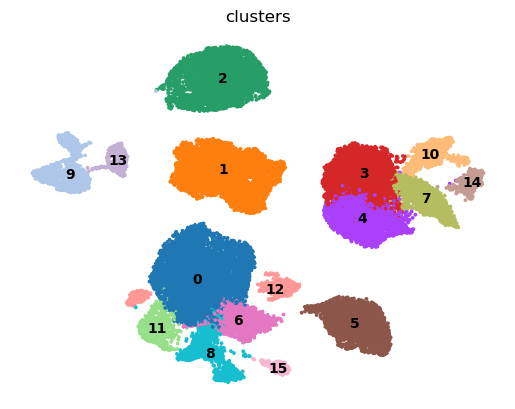

In [3]:
adata = run_pipeline_integrate(paths, n_components=n_components, resolution=0.4, is_10x=False)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [4]:
adata = adata[~adata.obs['clusters'].isin(['12'])].copy()

In [5]:
cluster_annotation = {
    "0": "Myeloid mononuclear cells",
    "1": "Malignant cells",
    "2": "Oligodendrocytes",
    "3": "T cells",
    "4": "T cells",
    "5": "Neutrophils",
    "6": "Myeloid mononuclear cells",
    "7": "T cells",
    "8": "Myeloid mononuclear cells",
    "9": "Pericytes",
    "10": "NK cells",
    "11": "Myeloid mononuclear cells",
 
    "13": "Endothelial cells",
    "14": "Cycling cells",
    "15": "Mast cells",
}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                 
0         Myeloid mononuclear cells    6956
1         Malignant cells              5446
2         Oligodendrocytes             4111
3         T cells                      4007
4         T cells                      2906
5         Neutrophils                  2351
6         Myeloid mononuclear cells    1479
7         T cells                      1443
8         Myeloid mononuclear cells    1227
9         Pericytes                    1069
10        NK cells                      894
11        Myeloid mononuclear cells     696
13        Endothelial cells             340
14        Cycling cells                 338
15        Mast cells                    210
Name: count, dtype: int64

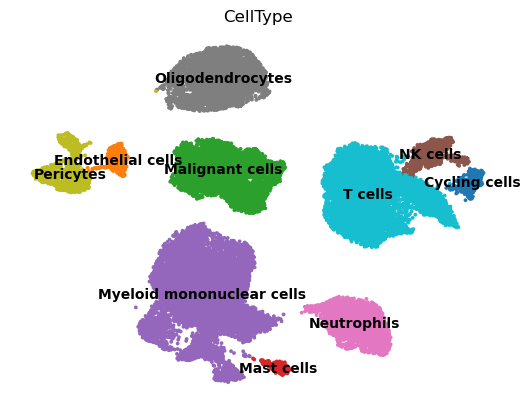

In [6]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [8]:
data_path / f"{type}_integrated_adata.h5ad"

PosixPath('part_2/LUAD_met/LUAD_met_integrated_adata.h5ad')

In [7]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Gallbladder metastasis

In [11]:
type = "GBC_met"
data_path = path / type 

paths = [data_path / str(i) for i in [1, 2]]
paths

[PosixPath('part_2/GBC_met/1'), PosixPath('part_2/GBC_met/2')]

Integration concat join='outer': per-sample genes [33538, 33538] -> combined 21491 genes × 7621 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-11-02 17:50:03,638 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-02 17:50:04,176 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-11-02 17:50:04,200 - harmonypy - INFO - Iteration 1 of 10
2026-11-02 17:50:06,587 - harmonypy - INFO - Iteration 2 of 10
2026-11-02 17:50:08,381 - harmonypy - INFO - Iteration 3 of 10
2026-11-02 17:50:09,98

*********************
7621 cells, 21491 genes
*********************


/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:396: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")
/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:398: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")["names"]


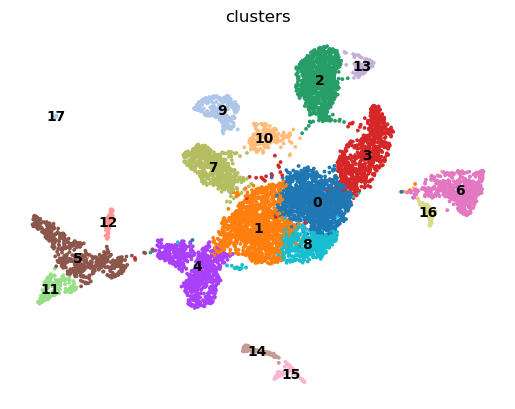

In [12]:
adata = run_pipeline_integrate(paths, n_components=20, resolution=0.5, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [13]:
adata = adata[~adata.obs['clusters'].isin(['10', '17'])]

In [14]:
cluster_annotation = {
    "0": "T cells",
    "1": "T cells",
    "2": "B cells",
    "3": "T cells",
    "4": "NK cells",
    "5": "Myeloid mononuclear cells",
    "6": "Malignant cells",
    "7": "T cells",
    "8": "T cells",
    "9": "Plasma cells",

    "11": "Myeloid mononuclear cells",
    "12": "Myeloid mononuclear cells",
    "13": "B cells",
    "14": "Endothelial cells",
    "15": "Fibroblasts",
    "16": "Malignant cells",

}
adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

/var/folders/np/46xyw0ds0t7g3v5c2ywcpmpc0000gn/T/ipykernel_49417/3977412631.py:21: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)


clusters  CellType                 
0         T cells                      1294
1         T cells                      1198
2         B cells                       900
3         T cells                       709
4         NK cells                      685
5         Myeloid mononuclear cells     504
6         Malignant cells               490
7         T cells                       463
8         T cells                       423
9         Plasma cells                  242
11        Myeloid mononuclear cells     149
12        Myeloid mononuclear cells      85
13        B cells                        84
14        Endothelial cells              81
15        Fibroblasts                    78
16        Malignant cells                59
Name: count, dtype: int64

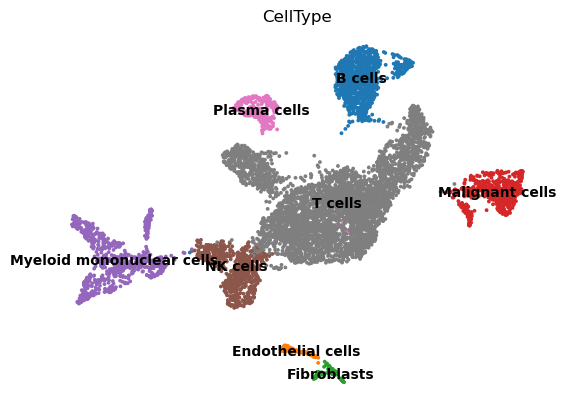

In [15]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [63]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Ovarian metastasis

In [64]:
type = "ovarian_met"
data_path = path / type 

paths = [data_path / str(i) / os.listdir(data_path / str(i))[0] for i in range(1, 6)]
paths

[PosixPath('part_2/ovarian_met/1/GSM4416538_PT-3401.csv.gz'),
 PosixPath('part_2/ovarian_met/2/GSM4416537_PT-4806.csv.gz'),
 PosixPath('part_2/ovarian_met/3/GSM4416536_PT-6885.csv.gz'),
 PosixPath('part_2/ovarian_met/4/GSM4416535_PT-5150.csv.gz'),
 PosixPath('part_2/ovarian_met/5/GSM4416534_PT-3232.csv.gz')]

Integration concat join='outer': per-sample genes [32024, 26499, 24063, 24776, 19297] -> combined 33063 genes × 7852 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-30 15:52:18,509 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-30 15:52:18,839 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-30 15:52:18,851 - harmonypy - INFO - Iteration 1 of 10
2026-10-30 15:52:19,360 - harmonypy - INFO - Iteration 2 of 10
2026-10-30 15:52:20,019 - harmonypy - INFO - Iteration 3 of 10
2026-10-30 15:52:20,582 - harmonypy - INFO - Iteration 4 of 10
2026-10-30 15:52:21,089 - harmonypy - INFO - Iteration 5 of 10
2026-10-30 15:52:21,602 - harmonypy - INFO - Iteration 6 of 10
2026-10-30 15:52:22,175 - harmonypy

*********************
7852 cells, 33063 genes
*********************


/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:396: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")
/Volumes/Transcend/work/miR_study/ss_datasets/before_miR/sc_scripts.py:398: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")["names"]


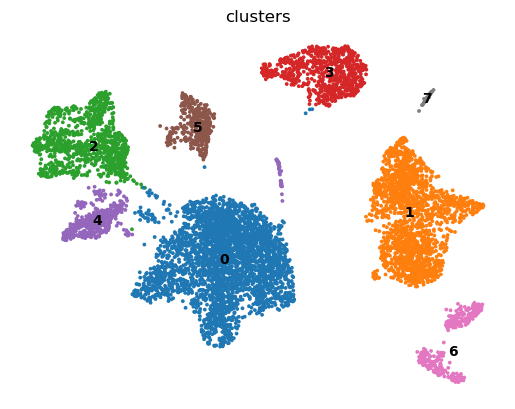

In [75]:
adata = run_pipeline_integrate(paths, n_components=20, resolution=0.1, is_10x=False)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [76]:
adata = adata[~adata.obs['clusters'].isin(['7'])].copy()

In [77]:
cluster_annotation = {
    "0": "Malignant cells",
    "1": "Fibroblasts",
    "2": "T cells",
    "3": "Myeloid mononuclear cells",
    "4": "B cells",
    "5": "Plasma cells",
    "6": "Endothelial cells",

}

adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                 
0         Malignant cells              3189
1         Fibroblasts                  1765
2         T cells                      1005
3         Myeloid mononuclear cells     747
4         B cells                       451
5         Plasma cells                  343
6         Endothelial cells             313
Name: count, dtype: int64

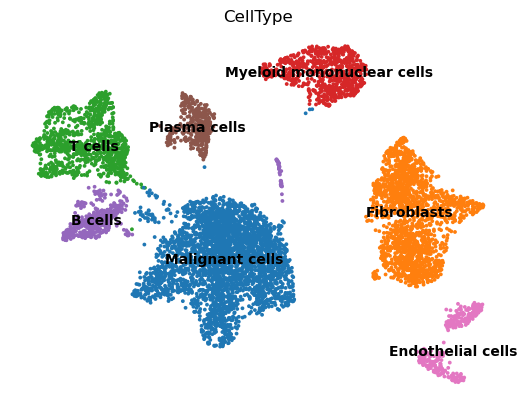

In [78]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [79]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# PBMC

In [80]:
type = "pbmc"
data_path = path / type 

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_2/pbmc/1'),
 PosixPath('part_2/pbmc/2'),
 PosixPath('part_2/pbmc/3'),
 PosixPath('part_2/pbmc/4'),
 PosixPath('part_2/pbmc/5')]

Integration concat join='outer': per-sample genes [36601, 36601, 36601, 36601, 36601] -> combined 22576 genes × 66407 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-30 16:17:11,539 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-30 16:17:13,662 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-30 16:17:13,760 - harmonypy - INFO - Iteration 1 of 10
2026-10-30 16:17:21,021 - harmonypy - INFO - Iteration 2 of 10
2026-10-30 16:17:28,492 - harmonypy - INFO - Iteration 3 of 10
2026-10-30 16:17:36,47

*********************
66407 cells, 22576 genes
*********************


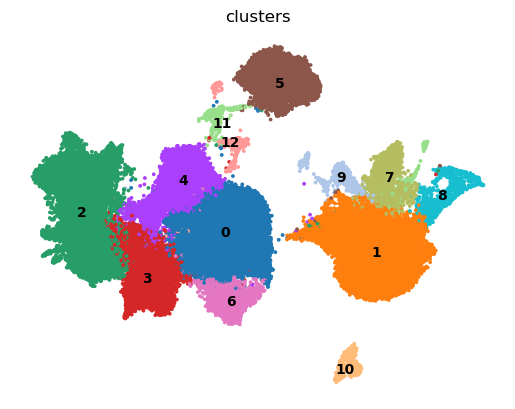

In [85]:
adata = run_pipeline_integrate(paths, n_components=50, resolution=0.4, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [86]:
adata = adata[~adata.obs['clusters'].isin(['11', '12'])].copy()

In [87]:
cluster_annotation = {
    "0": "Tregs",
    "1": "Classical monocytes",
    "2": "NK cells",
    "3": "MAIT T cells",
    "4": "CD4+ T cells",
    "5": "B cells",
    "6": "CD8+ T cells",
    "7": "Non-classical monocytes",
    "8": "Platelets",
    "9": "Dendritic cells",
    "10": "Plasmacytoid dendritic cells", 
}

adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                    
0         Tregs                           17172
1         Classical monocytes             12491
2         NK cells                        11585
3         MAIT T cells                     6871
4         CD4+ T cells                     6616
5         B cells                          4658
6         CD8+ T cells                     2461
7         Non-classical monocytes          1786
8         Platelets                         905
9         Dendritic cells                   706
10        Plasmacytoid dendritic cells      438
Name: count, dtype: int64

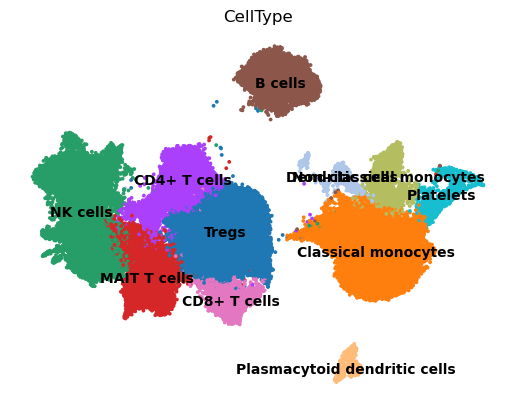

In [89]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [90]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Thyroid mets

In [94]:
type = "thyroid_met"
data_path = path / type 

paths = [data_path / str(i) for i in range(1, 6)]
paths

[PosixPath('part_2/thyroid_met/1'),
 PosixPath('part_2/thyroid_met/2'),
 PosixPath('part_2/thyroid_met/3'),
 PosixPath('part_2/thyroid_met/4'),
 PosixPath('part_2/thyroid_met/5')]

Integration concat join='outer': per-sample genes [33694, 33694, 33694, 33694, 33694] -> combined 24052 genes × 34550 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-10-30 17:16:24,910 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-30 17:16:25,957 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-30 17:16:26,015 - harmonypy - INFO - Iteration 1 of 10
2026-10-30 17:16:28,844 - harmonypy - INFO - Iteration 2 of 10
2026-10-30 17:16:31,752 - harmonypy - INFO - Iteration 3 of 10
2026-10-30 17:16:34,62

*********************
34550 cells, 24052 genes
*********************


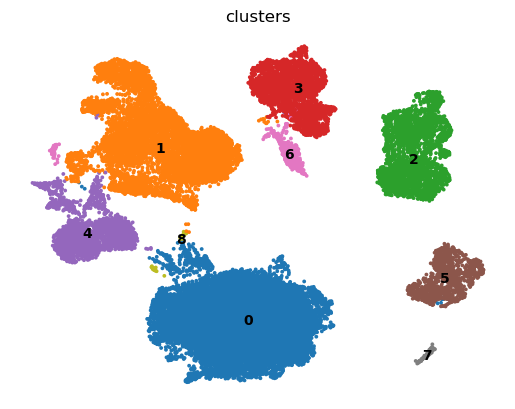

In [98]:
adata = run_pipeline_integrate(paths, n_components=n_components, resolution=res, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [99]:
adata = adata[~adata.obs['clusters'].isin(['7', '8'])].copy()

In [100]:
cluster_annotation = {
    "0": "Malignant cells",
    "1": "T cells",
    "2": "Fibroblasts",
    "3": "Myeloid mononuclear cells",
    "4": "B cells",
    "5": "Endothelial cells",
    "6": "Plasmacytoid dendritic cells",
}

adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                    
0         Malignant cells                 16636
1         T cells                          8296
2         Fibroblasts                      2803
3         Myeloid mononuclear cells        2586
4         B cells                          2317
5         Endothelial cells                1189
6         Plasmacytoid dendritic cells      554
Name: count, dtype: int64

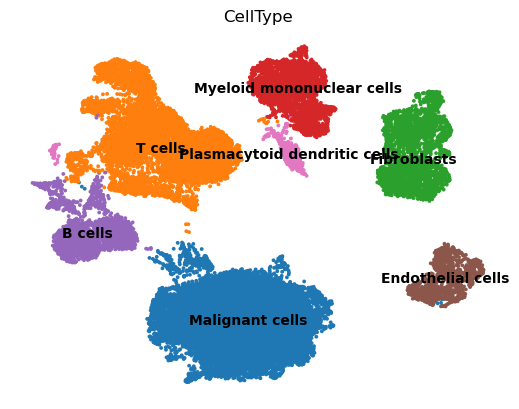

In [101]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [102]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

# Gallbladder

In [ ]:
type = "GBC"

data_path = path / type 

paths = [data_path / str(i) for i in range(1, 3)]
paths

[PosixPath('part_2/GBC/1'), PosixPath('part_2/GBC/2')]

Integration concat join='outer': per-sample genes [33538, 33538] -> combined 23016 genes × 11344 cells


/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/opt/homebrew/Caskroom/mambaforge/base/envs/singlecell/lib/python3.11/site-packages/scanpy/preprocessing/_pca/__init__.py:226: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(
2026-11-06 11:45:43,498 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-06 11:45:44,570 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-11-06 11:45:44,595 - harmonypy - INFO - Iteration 1 of 10
2026-11-06 11:45:46,081 - harmonypy - INFO - Iteration 2 of 10
2026-11-06 11:45:47,466 - harmonypy - INFO - Converged after 2 iterations


*********************
11344 cells, 23016 genes
*********************


/Volumes/Transcend/work/miR_study/ss_datasets/sc_scripts.py:396: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")
/Volumes/Transcend/work/miR_study/ss_datasets/sc_scripts.py:398: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group")["names"]


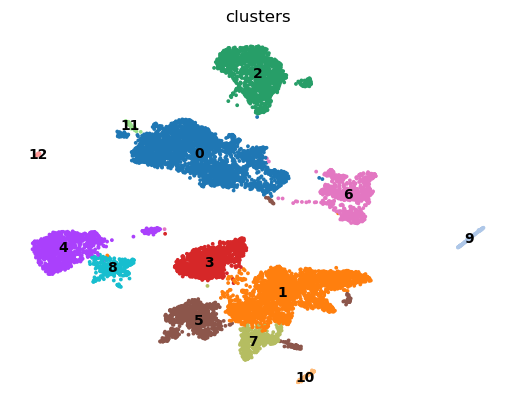

In [5]:
adata = run_pipeline_integrate(paths, n_components=50, resolution=0.2, is_10x=True)

markers = find_top_markers(adata, top_k=30)
with open(data_path / "markers.json", "w") as f:
    json.dump(markers, f, indent=4)

    
print('*********************')
print(f'{adata.shape[0]} cells, {adata.shape[1]} genes')
print('*********************')
sc.pl.umap(adata, color=['clusters'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [6]:
adata = adata[~adata.obs['clusters'].isin(['12'])].copy()

In [7]:
cluster_annotation = {
    "0": "Malignant cells",
    "11": "Malignant cells",
    
    "1": "T cells",
    "5": "T cells",
    "7": "NK cells",
    "2": "Fibroblasts",
    "3": "B cells",
    
    "4": "Myeloid mononuclear cells",
    "8": "Myeloid mononuclear cells",

    "6": "Plasma cells",
    "9": "Endothelial cells",
    "10": "Mast cells",
}

adata.obs["CellType"] = adata.obs["clusters"].map(cluster_annotation)
adata.obs[["clusters", "CellType"]].value_counts()

clusters  CellType                 
0         Malignant cells              2985
1         T cells                      2527
2         Fibroblasts                  1298
3         B cells                      1055
4         Myeloid mononuclear cells     981
5         T cells                       914
6         Plasma cells                  747
7         NK cells                      335
8         Myeloid mononuclear cells     295
9         Endothelial cells              81
10        Mast cells                     73
11        Malignant cells                33
Name: count, dtype: int64

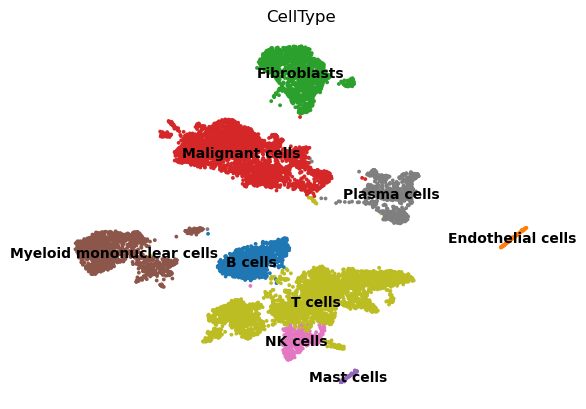

In [10]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)

In [9]:
adata.write(data_path / f"{type}_integrated_adata.h5ad")

In [12]:
adata = sc.read_h5ad(data_path / f"{type}_integrated_adata.h5ad")

In [ ]:
sc.pl.umap(adata, color=['CellType'], legend_loc="on data", size=30, alpha=1, frameon=False)